In [1]:
!pip install ultralytics ensemble-boxes
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 86.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 115.7 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10


In [2]:
from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
import numpy as np
import glob, os

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="API-KEY")
project = rf.workspace("WORKSPACE_NAME").project("PROJECT_NAME")
version = project.version(19)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Secret1-19 in yolov11:: 100%|██████████| 2290/2290 [00:00<00:00, 5860.44it/s]


# **YOLOv8n**

In [ ]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = r"D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov8n.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="yolo8n",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.202  Python-3.9.23 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 950M, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000025521E74C70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("yolo8n/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob(r"D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\test\images\*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="yolo8n", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Ultralytics 8.3.202  Python-3.9.23 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 950M, 4096MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.30.1 ms, read: 119.839.2 MB/s, size: 36.9 KB)
val: Scanning D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\valid\labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 205.4Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.5it/s 8.7s0.4s
                   all        206        221      0.994      0.979      0.994      0.817
          O.celebensis        160        173      0.994      0.957      0.992      0.829
           O.javanicus         46         48      0.994          1      0.995      0.806
Speed: 1.5ms preprocess, 26.7ms inference, 0.1ms loss, 5.8ms postprocess per image
Results saved to C:\Users\mamat\Galaxy-ALPR-App\runs\detect\val54

🔹 Ev

<Figure size 1800x1200 with 9 Axes>

# **YOLOv8s**

In [ ]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = r"D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov8s.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="yolo8s",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.202  Python-3.9.23 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 950M, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000255223010D0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("yolo8s/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob(r"D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\test\images\*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="yolo8s", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Ultralytics 8.3.202  Python-3.9.23 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 950M, 4096MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.30.1 ms, read: 27.960.3 MB/s, size: 44.5 KB)
val: Scanning D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\valid\labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 206.0Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 0.9it/s 14.6s0.9s
                   all        206        221      0.994      0.979      0.993      0.829
          O.celebensis        160        173      0.994      0.959      0.992      0.833
           O.javanicus         46         48      0.995          1      0.995      0.824
Speed: 5.2ms preprocess, 48.9ms inference, 0.0ms loss, 6.0ms postprocess per image
Results saved to C:\Users\mamat\Galaxy-ALPR-App\runs\detect\val55

🔹 

<Figure size 1800x1200 with 9 Axes>

# **YOLOv8m**

In [ ]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = r"D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov8m.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="yolo8m",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.202  Python-3.9.23 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 950M, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000028A03E9E340>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("yolo8m/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob(r"D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\test\images\*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="yolo8m", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Ultralytics 8.3.202  Python-3.9.23 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 950M, 4096MiB)
Model summary (fused): 92 layers, 25,840,918 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.20.0 ms, read: 168.050.5 MB/s, size: 36.9 KB)
val: Scanning D:\Penelitian Medaka (Code) (ONGOING)\Secret1.v19-experiment-1-balance.yolov8\valid\labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 200.2Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 0.2it/s 53.4s4.1ss
                   all        206        221      0.994      0.982      0.993      0.823
          O.celebensis        160        173      0.994      0.963      0.991      0.839
           O.javanicus         46         48      0.993          1      0.995      0.808
Speed: 3.6ms preprocess, 246.3ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to C:\Users\mamat\Galaxy-ALPR-App\runs\detect\val56


<Figure size 1800x1200 with 9 Axes>

# **YOLOv8l**

In [4]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = r"/content/Secret1-19/data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov8l.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="runs/yolo8l",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.202 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Secret1-19/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8l.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78c025eced50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Ultralytics 8.3.202 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 112 layers, 43,608,150 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1537.1±419.9 MB/s, size: 36.9 KB)
val: Scanning /content/Secret1-19/valid/labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 284.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.4it/s 9.5s
                   all        206        221          1      0.976      0.993      0.801
          O.celebensis        160        173          1      0.956       0.99      0.811
           O.javanicus         46         48          1      0.996      0.995      0.791
Speed: 0.2ms preprocess, 40.6ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val

🔹 Evaluation Metrics:
mAP50:     0.9927
mAP50-95:  0.8009
Precision: 1.0000
Recall:    0.9757

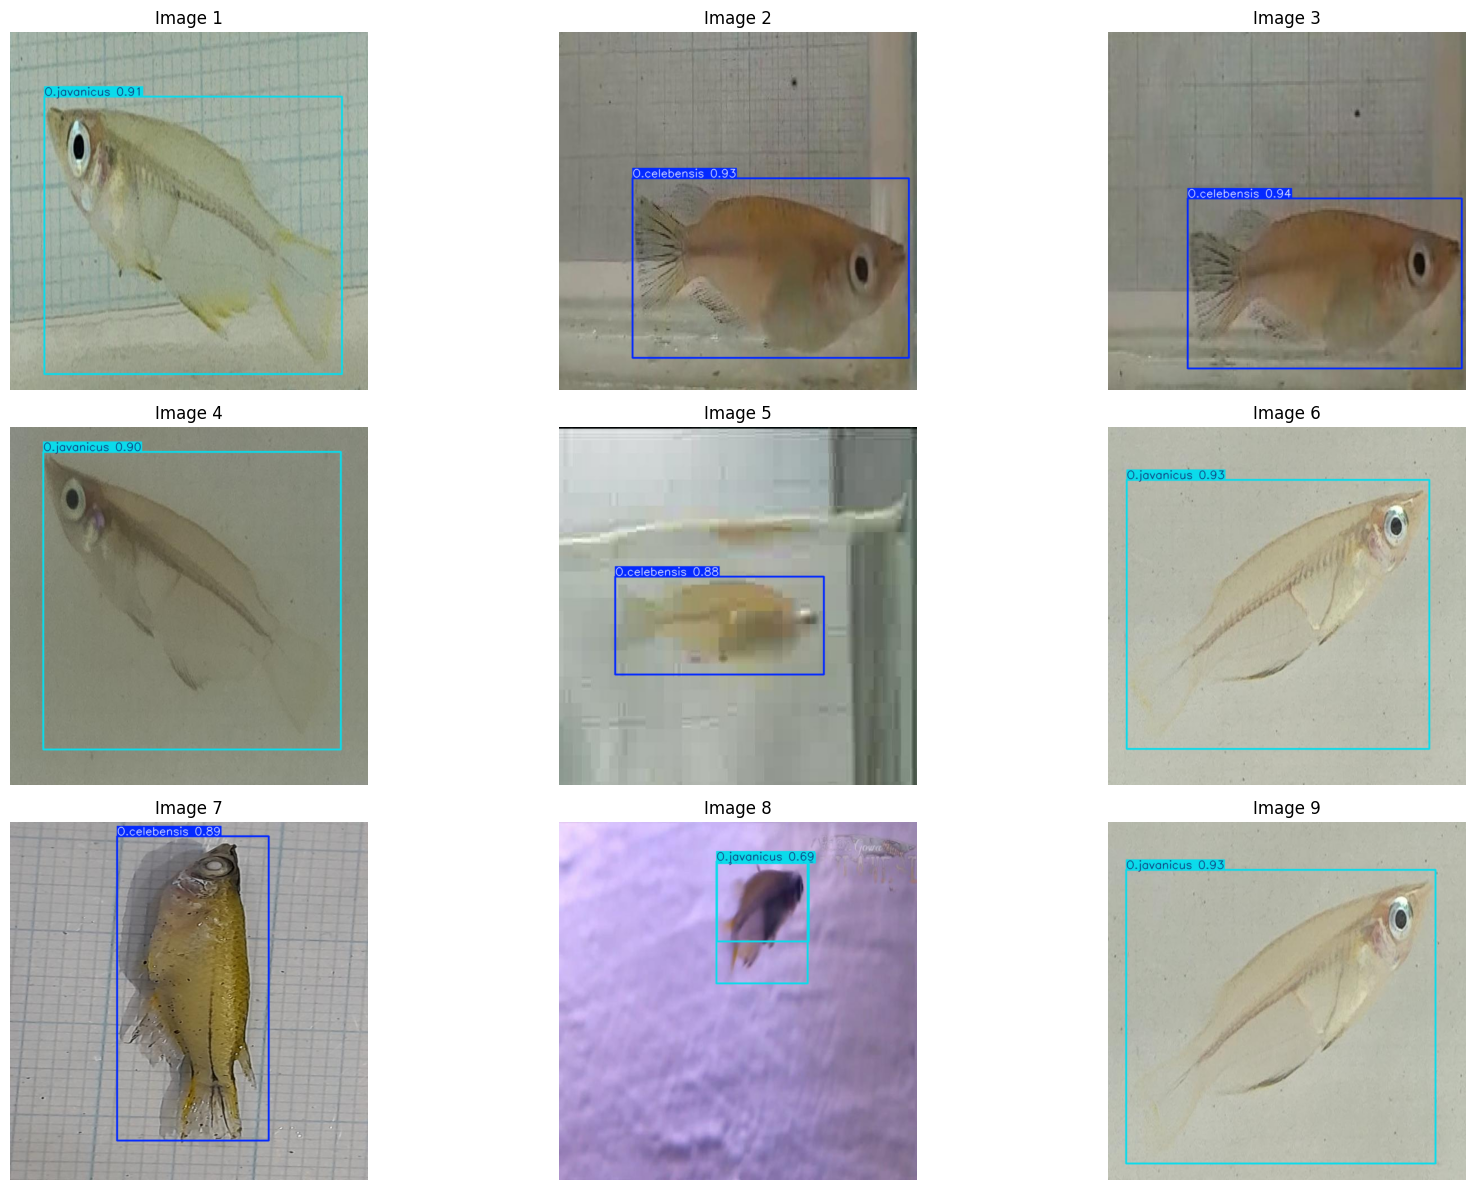

In [5]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("runs/yolo8l/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob(r"/content/Secret1-19/test/images/*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="yolo8l", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:
import shutil

# Folder you want to zip
folder_path = "/content/runs/yolo8l"

# Output zip file (without .zip in the name)
shutil.make_archive("yolo8l", "zip", folder_path)

'/content/yolo8l.zip'

In [7]:
from google.colab import files
files.download("/content/yolo8l.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **YOLOv8x**

In [8]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = r"/content/Secret1-19/data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov8x.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="runs/yolo8x",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.202 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Secret1-19/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8x.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78c1afb95190>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Ultralytics 8.3.202 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 112 layers, 68,125,494 parameters, 0 gradients, 257.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1635.8±436.7 MB/s, size: 44.5 KB)
val: Scanning /content/Secret1-19/valid/labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 446.3Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 0.9it/s 14.6s
                   all        206        221      0.997      0.974       0.99      0.805
          O.celebensis        160        173          1      0.948      0.985      0.809
           O.javanicus         46         48      0.995          1      0.995      0.802
Speed: 1.5ms preprocess, 64.9ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val2

🔹 Evaluation Metrics:
mAP50:     0.9902
mAP50-95:  0.8051
Precision: 0.9975
Recall:    0.97

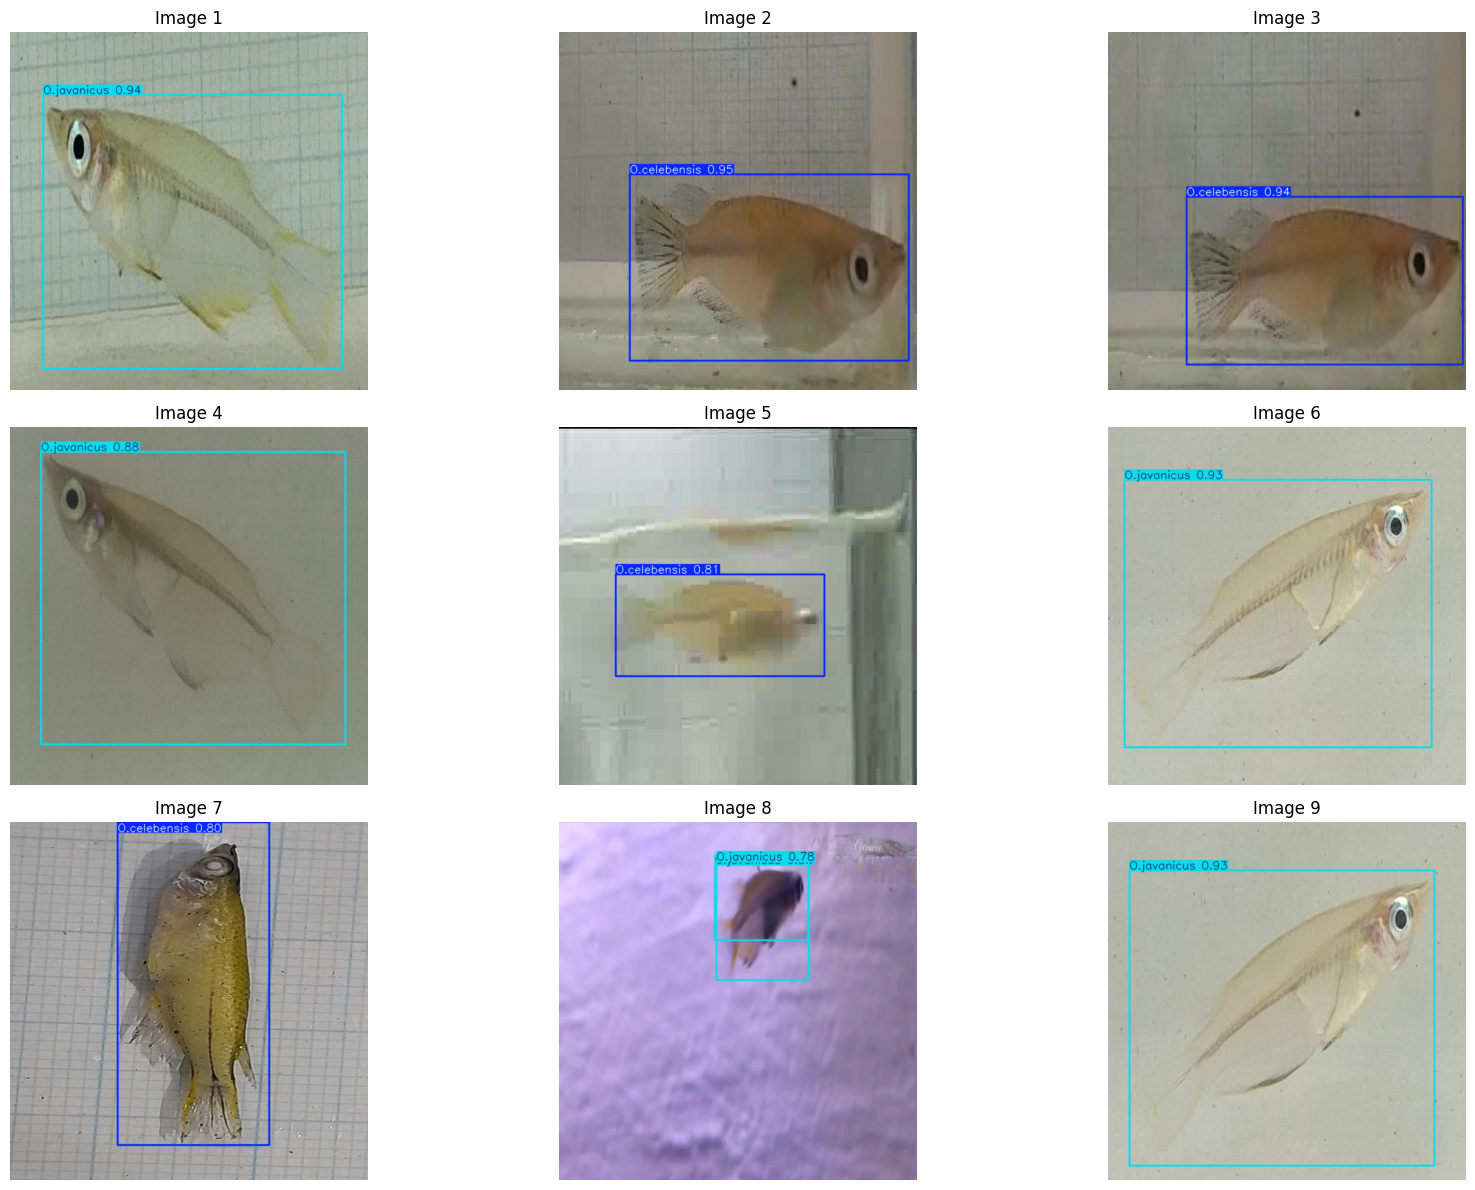

In [9]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("runs/yolo8x/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob(r"/content/Secret1-19/test/images/*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="yolo8x", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:
import shutil

# Folder you want to zip
folder_path = "/content/runs/yolo8x"

# Output zip file (without .zip in the name)
shutil.make_archive("yolo8x", "zip", folder_path)

'/content/yolo8x.zip'

In [11]:
from google.colab import files
files.download("/content/yolo8x.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>